# Evaluation

## Evaluate on different situation

### Load dataset and model

In [1]:
import argparse
import os.path

import torch
from torch import nn, optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm
from dataset.dataset_loader import VideoDataset
import torch.nn.functional as F
from eval_3c.utils import manhattan_dist, t3c, is_human
import random

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VideoDataset.add_model_specific_args(parser)
parser.add_argument('--data_path', type=str, default='dataset/ATR_1F_3F_2024-12-25_withtest')
# parser.add_argument('--data_path', type=str, default='dataset/mul_fps_data')

parser.add_argument('--sequence_length', type=int, default=40)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=100)
parser.add_argument('--iteration_num', type=int, default=1000)
args = parser.parse_args(args=[])
mulgpu = True
rgb = False

# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length,rgb=rgb, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

from utils import fw_diffusion_vid, fw_diffusion_mot, MixedSequenceMaskGenerator
input_mot_channel = args.sequence_length * 2
mask_generator = MixedSequenceMaskGenerator(t2=args.sequence_length)

# The parameters for forward diffusion process
beta = torch.linspace(1e-4, 0.02, args.iteration_num) 
alpha = 1.0-beta
alpha_cum = torch.tensor([alpha[0]] + [torch.prod(alpha[:i+1]) for i in range(1, len(beta))])


from TimeSformer.VDT_cat_vm import VDT_cat

nhead = 6
depth = 12
patch_size= 2
hidden_size = 768
epoch = 40
in_channels = 6
input_size = 8

eps_est_model = VDT_cat(
    input_size=input_size,
    patch_size=patch_size,
    in_channels=in_channels,
    hidden_size=hidden_size,
    depth=depth,
    num_frames=args.sequence_length,
    num_heads=nhead,
    mlp_ratio=4.0,
    learn_sigma=False
    ).to(DEVICE)


from diffusers.models import AutoencoderKL
vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse").to(DEVICE)
vae.encoder.conv_in = nn.Conv2d(9, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, 9, kernel_size=3, stride=1, padding=1)


if mulgpu:
    input_dim = 3
    modelData = 'checkpoints_vae_3c_seg/vae_20250202_seg40.pth.tar'
    checkpoint = torch.load(modelData)
    state_dict = checkpoint['model_state_dict']
    state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
else:
    modelData = 'checkpoints_vae_seg/vae_40.pth.tar'
    checkpoint = torch.load(modelData)
    state_dict = checkpoint['model_state_dict']
        

vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse")
vae.encoder.conv_in = nn.Conv2d(input_dim, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, input_dim, kernel_size=3, stride=1, padding=1)
vae.load_state_dict(state_dict)
vae.to(DEVICE)

# freeze vae
for param in vae.parameters():
    param.requires_grad = False





cuda:0
metadata exists in: dataset/ATR_1F_3F_2024-12-25_withtest/train/metadata_40.pkl
metadata exists in: dataset/ATR_1F_3F_2024-12-25_withtest/test/metadata_40.pkl


### Evaluate multiple real data's Manhattan distances and calculate the average

In [2]:
# 保留 is_human 为 True 的样本
def get_human_samples(dataset, num_samples):
    human_index = []
    while len(human_index) < num_samples:
        random_indices = random.sample(range(len(dataset)), num_samples - len(human_index))
        for idx in random_indices:
            sample,_,_ = dataset[idx]
            batch, mot = dict.values(sample)
            vid = t3c(batch).unsqueeze(0).to(DEVICE)
            if is_human(vid):
                human_index.append(idx)
        # print(len(human_index))
    return human_index

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=False, resolution=args.resolution)
human_index = get_human_samples(valid_dataset, 350)
torch.save(human_index, 'eval_action/action_index_350.pt')


metadata exists in: dataset/ATR_1F_3F_2024-12-25_withtest/test/metadata_40.pkl


In [4]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)
from eval_3c.utils import manhattan_dist, t3c, is_human, rpe

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=False, resolution=args.resolution)

all_rpe = []
action_index = torch.load('eval_action/action_index_350.pt')
sample_count = 0

print(len(action_index))
# 从数据集中抽取数据
for real_idx in action_index:
    dec_vid_list = []
    rec_mot_list = []

    batch, vid_idx, path = valid_dataset[real_idx]
    batch, mot = dict.values(batch)
    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
    vid = t3c(batch).to(DEVICE)

    dec_vid_list.append(vid)
    rec_mot_list.append(mot)


    # 随机抽取 n 个索引
    random_indices = random.sample(range(len(valid_dataset)), 50)

    # 从数据集中抽取数据
    for idx in random_indices:
        batch, vid_idx, path = valid_dataset[idx]
        batch, mot = dict.values(batch)
        mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
        vid = t3c(batch).to(DEVICE)

        dec_vid_list.append(vid)
        rec_mot_list.append(mot)

    frame_t = 10 
    rpe_distance = rpe(args, dec_vid_list, rec_mot_list, frame_t)
    all_rpe.append(rpe_distance)
    sample_count += 1
    print(sample_count)

# 将字典写入文件
torch.save(all_rpe, 'eval_action/action_all_rpe.pt')



metadata exists in: dataset/ATR_1F_3F_2024-12-25_withtest/test/metadata_40.pkl
350
Frame 1 RPE: {'translation': tensor(0.3479, device='cuda:0'), 'rotation': tensor(0.4020, device='cuda:0')}
Frame 2 RPE: {'translation': tensor(0.2242, device='cuda:0'), 'rotation': tensor(0.2910, device='cuda:0')}
Frame 3 RPE: {'translation': tensor(0.1483, device='cuda:0'), 'rotation': tensor(0.2016, device='cuda:0')}
Frame 4 RPE: {'translation': tensor(0.2016, device='cuda:0'), 'rotation': tensor(0.2472, device='cuda:0')}
Frame 5 RPE: {'translation': tensor(0.1568, device='cuda:0'), 'rotation': tensor(0.2324, device='cuda:0')}
Frame 6 RPE: {'translation': tensor(0.1808, device='cuda:0'), 'rotation': tensor(0.2394, device='cuda:0')}
Frame 7 RPE: {'translation': tensor(0.2238, device='cuda:0'), 'rotation': tensor(0.2852, device='cuda:0')}
Frame 8 RPE: {'translation': tensor(0.2253, device='cuda:0'), 'rotation': tensor(0.2863, device='cuda:0')}
Frame 9 RPE: {'translation': tensor(0.2110, device='cuda:0'),

In [5]:
import torch

# 读取 .pt 文件
all_distances = torch.load('eval_action/action_all_rpe.pt')
# print((all_distances))
# 初始化字典以存储排序后的结果
all_sorted_distances = []
channels = ['translation', 'rotation']

# print((all_distances))
for distances in all_distances:

    channel_distances = {channel: [] for channel in channels}
    sorted_sample_distances = {}
    for sample, distance in distances.items():
        for channel in channels:
            channel_distances[channel].append(distance[channel].item())
    
    for channel in channels:
        channel_distances[channel] = sorted(channel_distances[channel])

    all_sorted_distances.append(channel_distances)

# # 将结果存储为字典
# torch.save(all_sorted_distances, 'eval_3c/sorted_manhattan_distances_real_data.pt')

# 初始化字典以存储每个样本的平均曼哈顿距离
average_distances = {f'Sample {i+1}': {channel: 0 for channel in channels} for i in range(50)}
# print(average_distances)
# all_distances = torch.load('eval_3c/sorted_manhattan_distances_real_data.pt')

# 遍历所有曼哈顿距离，计算每个样本的总和
for distances in all_sorted_distances:
    for channel, distance in distances.items():
        for t, dist in enumerate(distance):
            # print(average_distances['Sample ' + str(t+1)][channel])
            average_distances['Sample ' + str(t+1)][channel] += dist

# 计算每个样本的平均曼哈顿距离
for t, distance in average_distances.items():
    average_distances[t] = {channel: torch.tensor(dist / len(all_sorted_distances)) for channel, dist in distance.items()}

# 打印每个样本的平均曼哈顿距离
print("Average rpe for Each Sample:")
for sample, means in average_distances.items():
    print(f"{sample}: {means}")

# 将结果存储为字典
torch.save(average_distances, 'eval_action/action_average_rpe_real_data.pt')

Average rpe for Each Sample:
Sample 1: {'translation': tensor(0.0209), 'rotation': tensor(0.0505)}
Sample 2: {'translation': tensor(0.0241), 'rotation': tensor(0.0516)}
Sample 3: {'translation': tensor(0.0261), 'rotation': tensor(0.0527)}
Sample 4: {'translation': tensor(0.0305), 'rotation': tensor(0.0568)}
Sample 5: {'translation': tensor(0.0390), 'rotation': tensor(0.0649)}
Sample 6: {'translation': tensor(0.0500), 'rotation': tensor(0.0766)}
Sample 7: {'translation': tensor(0.0638), 'rotation': tensor(0.0935)}
Sample 8: {'translation': tensor(0.0798), 'rotation': tensor(0.1119)}
Sample 9: {'translation': tensor(0.0950), 'rotation': tensor(0.1307)}
Sample 10: {'translation': tensor(0.1086), 'rotation': tensor(0.1470)}
Sample 11: {'translation': tensor(0.1210), 'rotation': tensor(0.1623)}
Sample 12: {'translation': tensor(0.1316), 'rotation': tensor(0.1747)}
Sample 13: {'translation': tensor(0.1392), 'rotation': tensor(0.1841)}
Sample 14: {'translation': tensor(0.1466), 'rotation': te

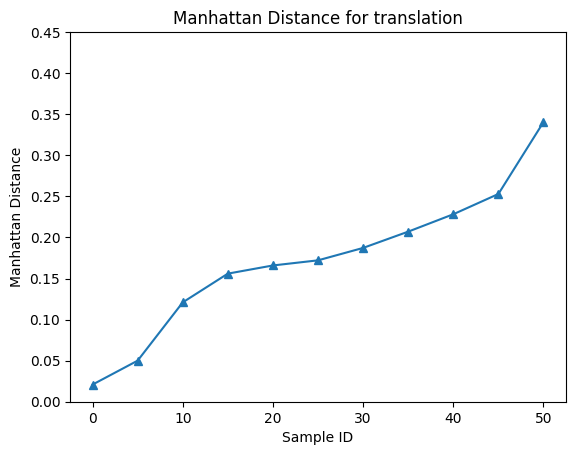

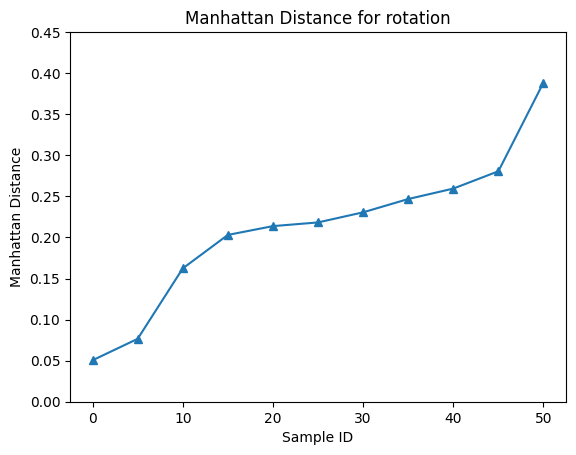

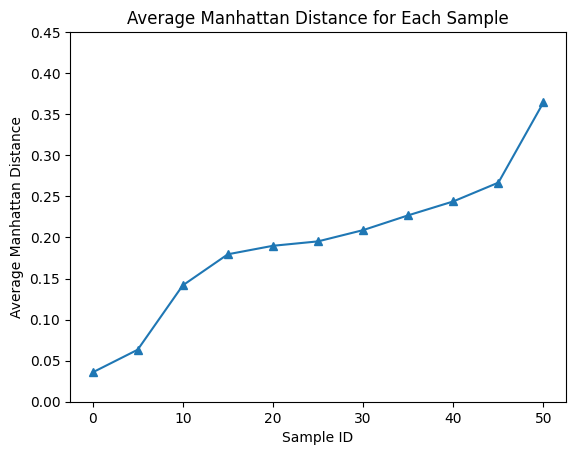

In [4]:
from eval_3c.utils import visual_rpe

# 读取 .pt 文件
distances = torch.load('eval_action/action_average_rpe_real_data.pt')
visual_rpe(distances)

### Evaluate real data v.s. generated samples

In [15]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)

from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray3c_2color
import time
from eval_3c.utils import manhattan_dist, t3c, rpe
import random

all_manhattan_distance = []

# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241031_halfmask_rgb_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
# modelData = 'checkpoints_mmVDT_vae_3c_seg/VDT_20250203_ATR_1F_3F_seg_3c_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
modelData = 'checkpoints_mmVDT_vae_3c_seg/VDT_20250210_testdata_ATR_1F_3F_seg_3c_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'

ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels, 
                                depth=depth, hidden_size=hidden_size, model_path=modelData, sequence_length=args.sequence_length,_cuda=0, cat=True)

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=False, resolution=args.resolution)

# 从数据集中抽取数据
action_index = torch.load('eval_action/action_index_350.pt')
sample_count = 0
for real_idx in action_index:
    vis_id = 0 # the index for visualization, default = 0
    pred_num = 50 # The number of multiple predictions
    frame_t = 10 
    sample_count += 1
    print(sample_count)

    test = True
    batch, vid_idx, path = valid_dataset[real_idx]
    print(vid_idx, path)
    batch, mot = dict.values(batch)

    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
    start_time = time.time()

    vid = t3c(batch).permute(0,3,1,2).to(DEVICE)
    enc_vid = vae.encode(vid).latent_dist.sample()
    enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)

    a = enc_vid.to(DEVICE)
    b = mot.to(DEVICE)
    rec_vid_list = []
    rec_mot_list = []
    dec_vid_list = []

    ################ Original image #############################
    batch = batch.permute(0,3,1,2)
    dec_vid_list.append(vid.permute(0,2,3,1))
    rec_mot_list.append(b[vis_id].reshape(1,args.sequence_length,2))

    if rgb:
        batch_rgb = batch
    else:
        batch_rgb = gray3c_2color(batch)
        batch_rgb = torch.clamp(batch_rgb, 0,1)

    rec_vid_list.append(batch_rgb.permute(0,2,3,1))  
    # visual_vid_mmot(batch_rgb.permute(0,2,3,1), b[vis_id].reshape(1,args.sequence_length,2), rgb=True, frame_t=frame_t,grid=False)

    if test:
        diff_a = torch.randn([pred_num,args.sequence_length,input_size,input_size,in_channels-2]).to(DEVICE)
        diff_b = torch.randn([pred_num,args.sequence_length,2]).to(DEVICE)

    # Choose a mask type from 0 to 2
    # 0: prediction 1: backward 2: interpolation, t means the current frame
    mask_vid, mask_motion, _ = mask_generator(diff_a,diff_b, idx=0, t=frame_t)

    ##################### Mask the video or not ##############################
    # mask_vid = torch.zeros_like(diff_a)
    ###########################################################################

    a = a.repeat(pred_num,1,1,1,1)
    b = b.repeat(pred_num,1,1)
    diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)

    with torch.no_grad():
        rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps
     
    rec_vid = rec_vid.reshape(pred_num,args.sequence_length,input_size,input_size,in_channels-2).permute(0,1,4,2,3)

    ################ Decode image #############################
    for i in range(pred_num):  
        rec_mot_list.append(rec_mot[i].reshape(1,args.sequence_length,2)) 
        # print(rec_vid[i].permute(0,2,3,1)[0,5,0])
        dec_vid = vae.decode(rec_vid[i]).sample
        dec_vid_list.append(dec_vid.permute(0,2,3,1))
        # print(dec_vid_list[i].shape)
        # if rgb:
        #     dec_rgb = torch.clamp(dec_vid, 0,1).permute(0,2,3,1)
        # else:
        #     dec_rgb = gray3c_2color(dec_vid)
        #     dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
        # rec_vid_list.append(dec_rgb)
    
    rpe_distance = rpe(args, dec_vid_list, rec_mot_list, frame_t)
    all_manhattan_distance.append(rpe_distance)

# 将字典写入文件
torch.save(all_manhattan_distance, 'eval_action/ation_no_guide_all_generated_rpe_500x50.pt')




load model: success
metadata exists in: dataset/ATR_1F_3F_2024-12-25_withtest/test/metadata_40.pkl
1
118 dataset/ATR_1F_3F_2024-12-25_withtest/test/data_2024-10-24-16_45_36_6m_in_419_sec/9.mp4
Frame 1 RPE: {'translation': tensor(0.1044, device='cuda:0'), 'rotation': tensor(0.1601, device='cuda:0')}
Frame 2 RPE: {'translation': tensor(0.1059, device='cuda:0'), 'rotation': tensor(0.1641, device='cuda:0')}
Frame 3 RPE: {'translation': tensor(0.1624, device='cuda:0'), 'rotation': tensor(0.2249, device='cuda:0')}
Frame 4 RPE: {'translation': tensor(0.0574, device='cuda:0'), 'rotation': tensor(0.0736, device='cuda:0')}
Frame 5 RPE: {'translation': tensor(0.1043, device='cuda:0'), 'rotation': tensor(0.1547, device='cuda:0')}
Frame 6 RPE: {'translation': tensor(0.1051, device='cuda:0'), 'rotation': tensor(0.1691, device='cuda:0')}
Frame 7 RPE: {'translation': tensor(0.1236, device='cuda:0'), 'rotation': tensor(0.1827, device='cuda:0')}
Frame 8 RPE: {'translation': tensor(0.1752, device='cuda:0

350
Average RPE for Each Sample:
Sample 1: {'translation': tensor(0.0312), 'rotation': tensor(0.0767)}
Sample 2: {'translation': tensor(0.0336), 'rotation': tensor(0.0799)}
Sample 3: {'translation': tensor(0.0352), 'rotation': tensor(0.0819)}
Sample 4: {'translation': tensor(0.0362), 'rotation': tensor(0.0834)}
Sample 5: {'translation': tensor(0.0373), 'rotation': tensor(0.0848)}
Sample 6: {'translation': tensor(0.0381), 'rotation': tensor(0.0859)}
Sample 7: {'translation': tensor(0.0388), 'rotation': tensor(0.0869)}
Sample 8: {'translation': tensor(0.0395), 'rotation': tensor(0.0878)}
Sample 9: {'translation': tensor(0.0402), 'rotation': tensor(0.0886)}
Sample 10: {'translation': tensor(0.0409), 'rotation': tensor(0.0894)}
Sample 11: {'translation': tensor(0.0416), 'rotation': tensor(0.0901)}
Sample 12: {'translation': tensor(0.0422), 'rotation': tensor(0.0909)}
Sample 13: {'translation': tensor(0.0428), 'rotation': tensor(0.0916)}
Sample 14: {'translation': tensor(0.0434), 'rotation'

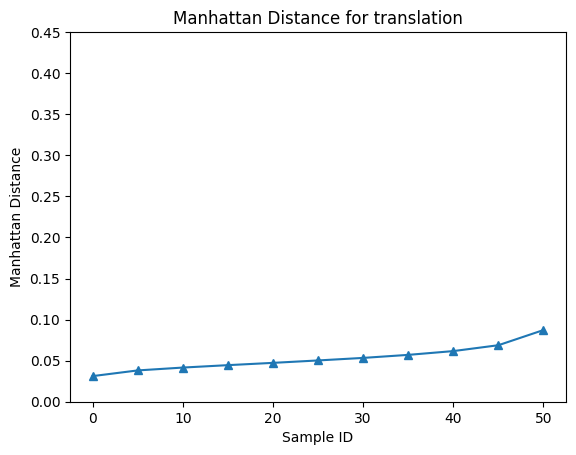

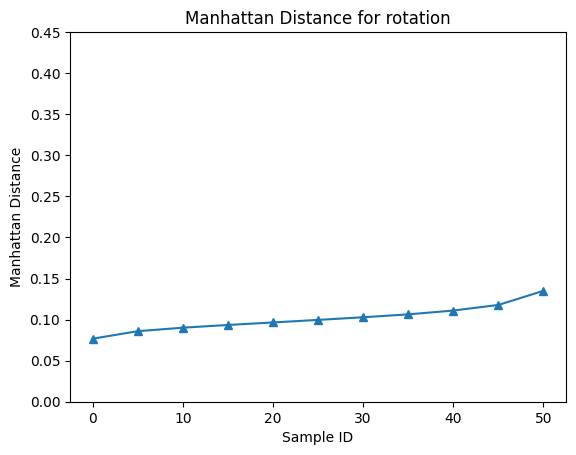

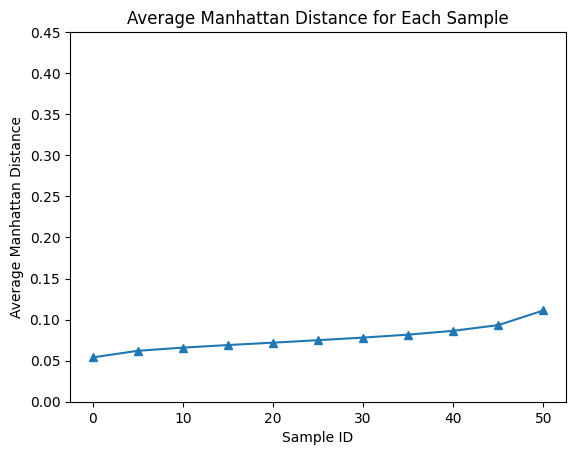

In [5]:
import torch

# 读取 .pt 文件
all_distances = torch.load('eval_action/ation_with_guide_all_generated_rpe_500x50.pt')

# 初始化字典以存储排序后的结果
all_sorted_distances = []
channels = ['translation', 'rotation']

print(len(all_distances))
for distances in all_distances:

    channel_distances = {channel: [] for channel in channels}
    sorted_sample_distances = {}
    for sample, distance in distances.items():
        for channel in channels:
            channel_distances[channel].append(distance[channel].item())
    
    for channel in channels:
        channel_distances[channel] = sorted(channel_distances[channel])

    all_sorted_distances.append(channel_distances)

# # 将结果存储为字典
# torch.save(all_sorted_distances, 'eval/sorted_manhattan_distances_generated.pt')

# 初始化字典以存储每个样本的平均曼哈顿距离
average_distances = {f'Sample {i+1}': {channel: 0 for channel in channels} for i in range(50)}
# print(average_distances)
# sorted_distances = torch.load('eval/sorted_manhattan_distances_generated.pt')

# 遍历所有曼哈顿距离，计算每个样本的总和
for distances in all_sorted_distances:
    for channel, distance in distances.items():
        for t, dist in enumerate(distance):
            # print(average_distances['Sample ' + str(t+1)][channel])
            average_distances['Sample ' + str(t+1)][channel] += dist

# 计算每个样本的平均曼哈顿距离
for t, distance in average_distances.items():
    average_distances[t] = {channel: torch.tensor(dist / len(all_sorted_distances)) for channel, dist in distance.items()}

# 打印每个样本的平均曼哈顿距离
print("Average RPE for Each Sample:")
for sample, means in average_distances.items():
    print(f"{sample}: {means}")

# 将结果存储为字典
torch.save(average_distances, 'eval_action/action_average_RPE_generated_with_guide.pt')

# Visualize the results
from eval_3c.utils import visual_rpe

# 读取 .pt 文件
distances = torch.load('eval_action/action_average_RPE_generated_with_guide.pt')
visual_rpe(distances)

## Summarize three figure in one

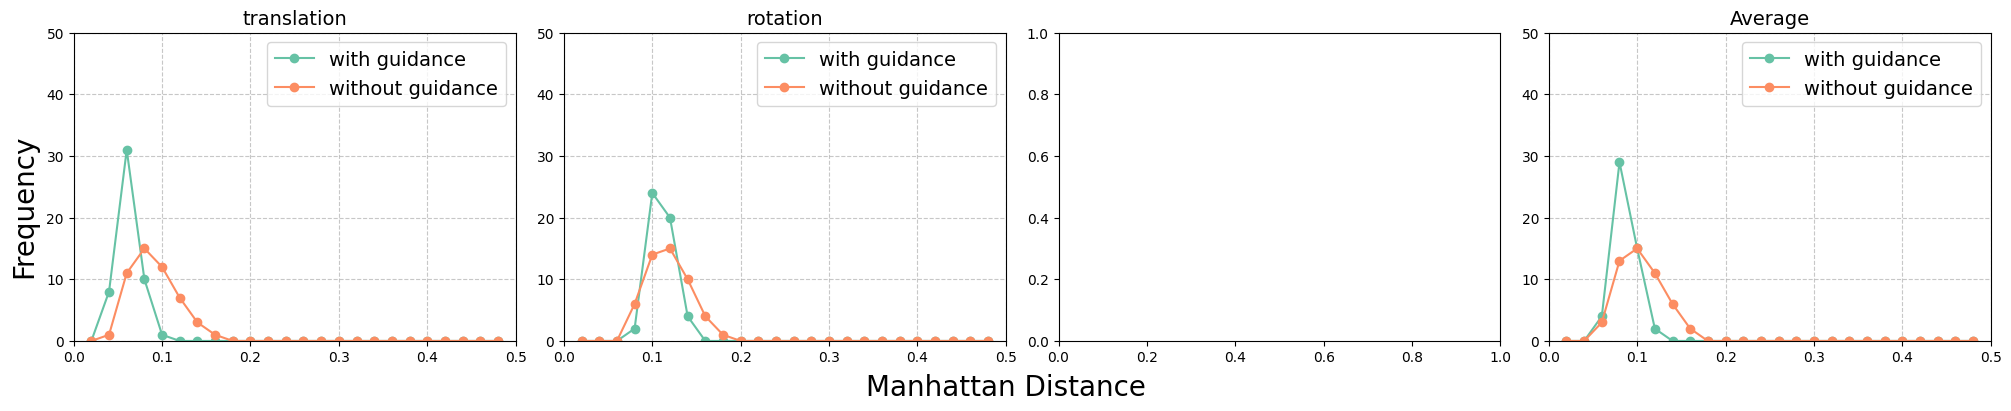

In [21]:
import torch
manhattan_distance_1 = torch.load('eval_3c/manhattan_distances_1.pt')
RPE_with_guide = torch.load('eval_action/action_average_RPE_generated_with_guide.pt')
RPE_without_guide = torch.load('eval_action/action_average_RPE_generated_no_guide.pt')
# print(manhattan_distance_2)
from eval_3c.utils import visual_MD_combined
visual_MD_combined(RPE_with_guide, RPE_without_guide, Freq=True, channel='RPE')    

In [23]:
import torch

# 假设 RPE_with_guide 是一个包含 50 个 sample 的列表，每个 sample 是一个字典，包含 translation 和 rotation 数据
RPE_with_guide = torch.load('eval_action/action_average_RPE_generated_with_guide.pt')
RPE_without_guide = torch.load('eval_action/action_average_RPE_generated_no_guide.pt')

# 初始化列表以存储所有 sample 的 translation 和 rotation 数据
translations_with_guide = []
rotations_with_guide = []

translations_without_guide = []
rotations_without_guide = []

# 遍历每个 sample，并分别提取 translation 和 rotation 数据
for sample, RPE in RPE_with_guide.items():
    translations_with_guide.append(RPE['translation'])
    rotations_with_guide.append(RPE['rotation'])

for sample, RPE in RPE_without_guide.items():
    translations_without_guide.append(RPE['translation'])
    rotations_without_guide.append(RPE['rotation'])

# 将列表转换为张量
translations_with_guide = torch.tensor(translations_with_guide)
rotations_with_guide = torch.tensor(rotations_with_guide)

translations_without_guide = torch.tensor(translations_without_guide)
rotations_without_guide = torch.tensor(rotations_without_guide)

# 计算 translation 的均值和方差
mean_translation_with_guide = torch.mean(translations_with_guide)
variance_translation_with_guide = torch.sqrt(torch.var(translations_with_guide))

mean_translation_without_guide = torch.mean(translations_without_guide)
variance_translation_without_guide = torch.sqrt(torch.var(translations_without_guide))

# 计算 rotation 的均值和方差
mean_rotation_with_guide = torch.mean(rotations_with_guide)
variance_rotation_with_guide = torch.sqrt(torch.var(rotations_with_guide))

mean_rotation_without_guide = torch.mean(rotations_without_guide)
variance_rotation_without_guide = torch.sqrt(torch.var(rotations_without_guide))

print(f"Translation with guide - Mean: {mean_translation_with_guide.item()}, Variance: {variance_translation_with_guide.item()}")
print(f"Translation without guide - Mean: {mean_translation_without_guide.item()}, Variance: {variance_translation_without_guide.item()}")
print(f"Rotation with guide - Mean: {mean_rotation_with_guide.item()}, Variance: {variance_rotation_with_guide.item()}")
print(f"Rotation without guide - Mean: {mean_rotation_without_guide.item()}, Variance: {variance_rotation_without_guide.item()}")

Translation with guide - Mean: 0.05163123458623886, Variance: 0.012080786749720573
Translation without guide - Mean: 0.08000407367944717, Variance: 0.02512933500111103
Rotation with guide - Mean: 0.10041441023349762, Variance: 0.012476927600800991
Rotation without guide - Mean: 0.10798124969005585, Variance: 0.023905783891677856
